In [1]:
# ============================================================
# 04.04 — THRESHOLD ANALYSIS
# CELL 1 — IMPORTS
# ============================================================

import os
import json
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score
)

print("=" * 60)
print("04.04 THRESHOLD ANALYSIS")
print("=" * 60)

print("NumPy version   :", np.__version__)
print("Pandas version  :", pd.__version__)

print("\nImports loaded successfully.")

04.04 THRESHOLD ANALYSIS
NumPy version   : 2.5.2
Pandas version  : 2.3.3

Imports loaded successfully.


In [2]:
# ============================================================
# CELL 2 — PATHS AND REPRODUCIBILITY
# ============================================================

PROJECT_ROOT = r"C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening"

CROSS_MODAL_ROOT = os.path.join(
    PROJECT_ROOT,
    "06_cross_modal_learning"
)

EVALUATION_ROOT = os.path.join(
    CROSS_MODAL_ROOT,
    "04_cross_modal_evaluation"
)

FIGURES_DIR = os.path.join(
    EVALUATION_ROOT,
    "figures"
)

REPORTS_DIR = os.path.join(
    EVALUATION_ROOT,
    "reports"
)

PROBABILITY_PREDICTIONS_PATH = os.path.join(
    REPORTS_DIR,
    "04_03_probability_predictions.csv"
)

os.makedirs(
    FIGURES_DIR,
    exist_ok=True
)

os.makedirs(
    REPORTS_DIR,
    exist_ok=True
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Project root:")
print(PROJECT_ROOT)

print("\nEvaluation root:")
print(EVALUATION_ROOT)

print("\nProbability predictions:")
print(PROBABILITY_PREDICTIONS_PATH)

print("\nFigures directory:")
print(FIGURES_DIR)

print("\nReports directory:")
print(REPORTS_DIR)

print("\nPath setup: PASSED")

Project root:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening

Evaluation root:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation

Probability predictions:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\reports\04_03_probability_predictions.csv

Figures directory:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\figures

Reports directory:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\reports

Path setup: PASSED


In [3]:
# ============================================================
# CELL 3 — LOAD PROBABILITY PREDICTIONS
# ============================================================

prediction_data = pd.read_csv(
    PROBABILITY_PREDICTIONS_PATH
)

print("Prediction data shape:")
print(prediction_data.shape)

print("\nColumns:")
print(
    prediction_data.columns.tolist()
)

print("\nFirst 5 rows:")
print(
    prediction_data.head().to_string(
        index=False
    )
)

assert len(prediction_data) == 448

assert (
    "predicted_probability"
    in prediction_data.columns
)

assert (
    "pair_label"
    in prediction_data.columns
)

print("\nPrediction artifact verification: PASSED")

Prediction data shape:
(448, 12)

Columns:
['source_modality', 'target_modality', 'source_index', 'target_index', 'source_class', 'target_class', 'pair_label', 'pair_type', 'logit', 'predicted_probability', 'predicted_class_at_0_5', 'correct_at_0_5']

First 5 rows:
source_modality target_modality  source_index  target_index  source_class  target_class  pair_label pair_type     logit  predicted_probability  predicted_class_at_0_5  correct_at_0_5
        Genetic      Behavioral            10           693             0             0           1  positive  0.201743               0.550265                       1            True
        Genetic      Behavioral            14           702             0             0           1  positive -1.208289               0.230004                       0           False
        Genetic      Behavioral            20           635             0             0           1  positive  0.048158               0.512037                       1            True
  

In [4]:
# ============================================================
# CELL 4 — EXTRACT LABELS AND PROBABILITIES
# ============================================================

y_true = prediction_data[
    "pair_label"
].astype(int).to_numpy()

probabilities = prediction_data[
    "predicted_probability"
].astype(float).to_numpy()

print("Labels shape       :", y_true.shape)
print("Probabilities shape:", probabilities.shape)

print("\nClass distribution:")

class_counts = pd.Series(
    y_true
).value_counts().sort_index()

print(class_counts)

print("\nProbability statistics:")

print(
    f"Mean : {probabilities.mean():.10f}"
)

print(
    f"Std  : {probabilities.std():.10f}"
)

print(
    f"Min  : {probabilities.min():.10f}"
)

print(
    f"Max  : {probabilities.max():.10f}"
)

assert y_true.shape == (448,)
assert probabilities.shape == (448,)

assert np.isfinite(y_true).all()
assert np.isfinite(probabilities).all()

assert set(np.unique(y_true)).issubset({0, 1})

assert np.all(
    (probabilities >= 0) &
    (probabilities <= 1)
)

assert np.sum(y_true == 0) == 224
assert np.sum(y_true == 1) == 224

print("\nLabel and probability verification: PASSED")

Labels shape       : (448,)
Probabilities shape: (448,)

Class distribution:
0    224
1    224
Name: count, dtype: int64

Probability statistics:
Mean : 0.5153837036
Std  : 0.2105154802
Min  : 0.0326929200
Max  : 0.9379036000

Label and probability verification: PASSED


In [5]:
# ============================================================
# CELL 5 — OFFICIAL ROC-AUC VERIFICATION
# ============================================================

roc_auc = roc_auc_score(
    y_true,
    probabilities
)

official_roc_auc = 0.6626674107142857

print("ROC-AUC from 04.03 predictions:")
print(
    f"{roc_auc:.10f}"
)

print("\nOfficial baseline ROC-AUC:")
print(
    f"{official_roc_auc:.10f}"
)

auc_difference = abs(
    roc_auc - official_roc_auc
)

print("\nAbsolute difference:")
print(
    f"{auc_difference:.12f}"
)

assert auc_difference < 1e-6

print("\nOfficial ROC-AUC verification: PASSED")

ROC-AUC from 04.03 predictions:
0.6626674107

Official baseline ROC-AUC:
0.6626674107

Absolute difference:
0.000000000000

Official ROC-AUC verification: PASSED


In [6]:
# ============================================================
# CELL 6 — DEFINE THRESHOLDS
# ============================================================

thresholds = np.round(
    np.arange(
        0.10,
        0.901,
        0.05
    ),
    2
)

print("Thresholds to evaluate:")

print(
    thresholds
)

print(
    "\nNumber of thresholds:",
    len(thresholds)
)

assert thresholds[0] == 0.10
assert thresholds[-1] == 0.90
assert len(thresholds) == 17

assert np.all(
    np.diff(thresholds) > 0
)

print("\nThreshold definition: PASSED")

Thresholds to evaluate:
[0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7  0.75
 0.8  0.85 0.9 ]

Number of thresholds: 17

Threshold definition: PASSED


In [7]:
# ============================================================
# CELL 7 — COMPLETE THRESHOLD SWEEP
# ============================================================

threshold_results = []

for threshold in thresholds:

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(
        y_true,
        predictions
    )

    balanced_accuracy = balanced_accuracy_score(
        y_true,
        predictions
    )

    precision = precision_score(
        y_true,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        predictions,
        zero_division=0
    )

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    f1 = f1_score(
        y_true,
        predictions,
        zero_division=0
    )

    youden_j = (
        recall
        +
        specificity
        -
        1.0
    )

    threshold_results.append({
        "threshold": float(threshold),
        "samples": int(len(y_true)),
        "predicted_class_0": int(np.sum(predictions == 0)),
        "predicted_class_1": int(np.sum(predictions == 1)),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "accuracy": float(accuracy),
        "balanced_accuracy": float(
            balanced_accuracy
        ),
        "precision": float(precision),
        "recall_sensitivity": float(
            recall
        ),
        "specificity": float(
            specificity
        ),
        "f1_score": float(f1),
        "youden_j": float(youden_j)
    })


threshold_df = pd.DataFrame(
    threshold_results
)

print(
    threshold_df.to_string(
        index=False
    )
)

assert len(threshold_df) == 17

assert (
    threshold_df["samples"] == 448
).all()

assert np.isfinite(
    threshold_df[
        [
            "accuracy",
            "balanced_accuracy",
            "precision",
            "recall_sensitivity",
            "specificity",
            "f1_score",
            "youden_j"
        ]
    ].to_numpy()
).all()

print("\nThreshold sweep calculation: PASSED")

 threshold  samples  predicted_class_0  predicted_class_1  tn  fp  fn  tp  accuracy  balanced_accuracy  precision  recall_sensitivity  specificity  f1_score  youden_j
      0.10      448                  7                441   7 217   0 224  0.515625           0.515625   0.507937            1.000000     0.031250  0.673684  0.031250
      0.15      448                 17                431  14 210   3 221  0.524554           0.524554   0.512761            0.986607     0.062500  0.674809  0.049107
      0.20      448                 34                414  27 197   7 217  0.544643           0.544643   0.524155            0.968750     0.120536  0.680251  0.089286
      0.25      448                 56                392  38 186  18 206  0.544643           0.544643   0.525510            0.919643     0.169643  0.668831  0.089286
      0.30      448                 81                367  53 171  28 196  0.555804           0.555804   0.534060            0.875000     0.236607  0.663283  0.11160

In [8]:
# ============================================================
# CELL 8 — THRESHOLD 0.50 OFFICIAL VERIFICATION
# ============================================================

threshold_050 = threshold_df[
    np.isclose(
        threshold_df["threshold"],
        0.50
    )
].iloc[0]

print("Threshold 0.50 results:")

print(
    threshold_050.to_string()
)

assert abs(
    threshold_050["accuracy"]
    - 0.6116071428571429
) < 1e-6

assert abs(
    threshold_050["precision"]
    - 0.6068376068376068
) < 1e-6

assert abs(
    threshold_050["recall_sensitivity"]
    - 0.6339285714285714
) < 1e-6

assert abs(
    threshold_050["specificity"]
    - 0.5892857142857143
) < 1e-6

assert abs(
    threshold_050["f1_score"]
    - 0.6200873362445415
) < 1e-6

assert threshold_050["tn"] == 132
assert threshold_050["fp"] == 92
assert threshold_050["fn"] == 82
assert threshold_050["tp"] == 142

print(
    "\nThreshold 0.50 verification: PASSED"
)

Threshold 0.50 results:
threshold               0.500000
samples               448.000000
predicted_class_0     214.000000
predicted_class_1     234.000000
tn                    132.000000
fp                     92.000000
fn                     82.000000
tp                    142.000000
accuracy                0.611607
balanced_accuracy       0.611607
precision               0.606838
recall_sensitivity      0.633929
specificity             0.589286
f1_score                0.620087
youden_j                0.223214

Threshold 0.50 verification: PASSED


In [9]:
# ============================================================
# CELL 9 — MAIN THRESHOLD METRICS TABLE
# ============================================================

main_threshold_table = threshold_df[
    [
        "threshold",
        "accuracy",
        "balanced_accuracy",
        "precision",
        "recall_sensitivity",
        "specificity",
        "f1_score",
        "youden_j"
    ]
].copy()

print(
    main_threshold_table.to_string(
        index=False
    )
)

print("\nMain threshold metrics table: READY")

 threshold  accuracy  balanced_accuracy  precision  recall_sensitivity  specificity  f1_score  youden_j
      0.10  0.515625           0.515625   0.507937            1.000000     0.031250  0.673684  0.031250
      0.15  0.524554           0.524554   0.512761            0.986607     0.062500  0.674809  0.049107
      0.20  0.544643           0.544643   0.524155            0.968750     0.120536  0.680251  0.089286
      0.25  0.544643           0.544643   0.525510            0.919643     0.169643  0.668831  0.089286
      0.30  0.555804           0.555804   0.534060            0.875000     0.236607  0.663283  0.111607
      0.35  0.591518           0.591518   0.560117            0.852679     0.330357  0.676106  0.183036
      0.40  0.604911           0.604911   0.577049            0.785714     0.424107  0.665406  0.209821
      0.45  0.604911           0.604911   0.585455            0.718750     0.491071  0.645291  0.209821
      0.50  0.611607           0.611607   0.606838            0.

In [10]:
# ============================================================
# CELL 10 — CONFUSION MATRIX COUNTS BY THRESHOLD
# ============================================================

confusion_threshold_table = threshold_df[
    [
        "threshold",
        "tn",
        "fp",
        "fn",
        "tp",
        "predicted_class_0",
        "predicted_class_1"
    ]
].copy()

print(
    confusion_threshold_table.to_string(
        index=False
    )
)

print(
    "\nConfusion-matrix threshold analysis: READY"
)

 threshold  tn  fp  fn  tp  predicted_class_0  predicted_class_1
      0.10   7 217   0 224                  7                441
      0.15  14 210   3 221                 17                431
      0.20  27 197   7 217                 34                414
      0.25  38 186  18 206                 56                392
      0.30  53 171  28 196                 81                367
      0.35  74 150  33 191                107                341
      0.40  95 129  48 176                143                305
      0.45 110 114  63 161                173                275
      0.50 132  92  82 142                214                234
      0.55 150  74  98 126                248                200
      0.60 166  58 114 110                280                168
      0.65 179  45 135  89                314                134
      0.70 196  28 150  74                346                102
      0.75 206  18 168  56                374                 74
      0.80 216   8 194  3

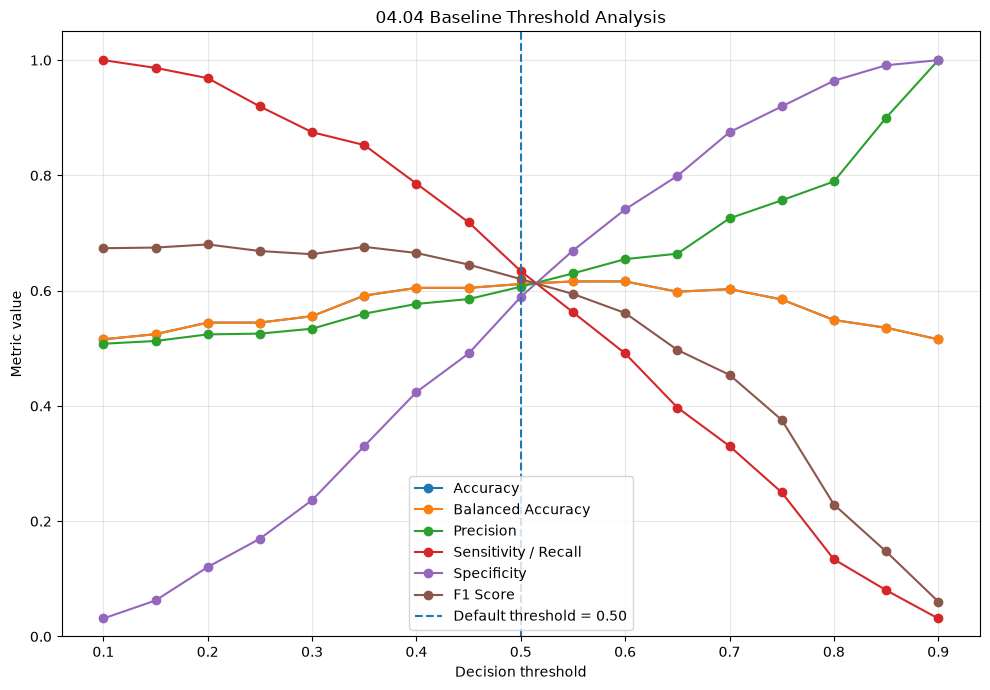


Saved: C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\figures\04_04_threshold_metrics_curve.png
Threshold curve verification: PASSED


In [11]:
# ============================================================
# CELL 11 — THRESHOLD METRICS CURVE
# ============================================================

threshold_curve_path = os.path.join(
    FIGURES_DIR,
    "04_04_threshold_metrics_curve.png"
)

plt.figure(
    figsize=(10, 7)
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["balanced_accuracy"],
    marker="o",
    label="Balanced Accuracy"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall_sensitivity"],
    marker="o",
    label="Sensitivity / Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["specificity"],
    marker="o",
    label="Specificity"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1_score"],
    marker="o",
    label="F1 Score"
)

plt.axvline(
    0.50,
    linestyle="--",
    label="Default threshold = 0.50"
)

plt.xlabel(
    "Decision threshold"
)

plt.ylabel(
    "Metric value"
)

plt.title(
    "04.04 Baseline Threshold Analysis"
)

plt.ylim(
    0,
    1.05
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.savefig(
    threshold_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

assert os.path.exists(
    threshold_curve_path
)

print(
    "\nSaved:",
    threshold_curve_path
)

print("Threshold curve verification: PASSED")

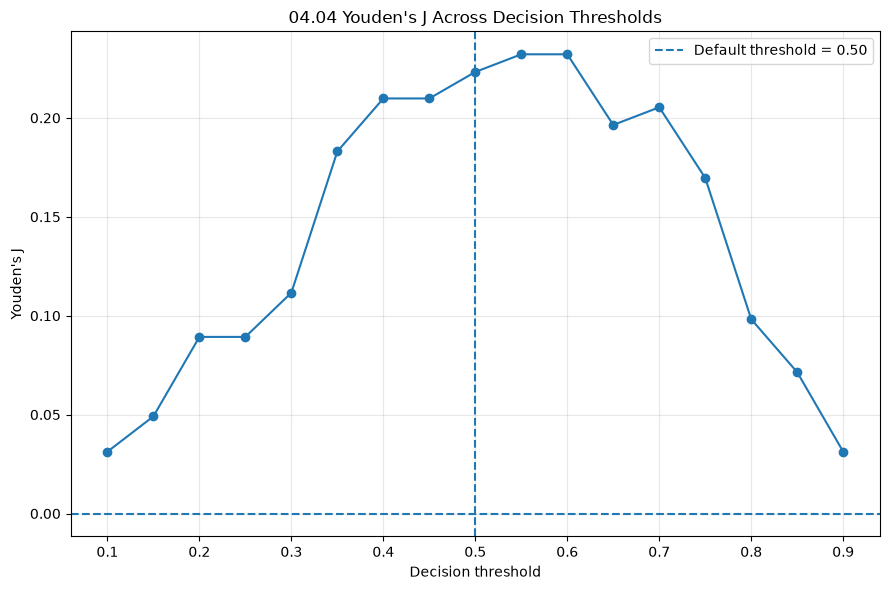


Saved: C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\figures\04_04_youden_j_threshold_curve.png
Youden's J figure verification: PASSED


In [12]:
# ============================================================
# CELL 12 — YOUDEN'S J ANALYSIS
# ============================================================

youden_figure_path = os.path.join(
    FIGURES_DIR,
    "04_04_youden_j_threshold_curve.png"
)

plt.figure(
    figsize=(9, 6)
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["youden_j"],
    marker="o"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.axvline(
    0.50,
    linestyle="--",
    label="Default threshold = 0.50"
)

plt.xlabel(
    "Decision threshold"
)

plt.ylabel(
    "Youden's J"
)

plt.title(
    "04.04 Youden's J Across Decision Thresholds"
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.savefig(
    youden_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

assert os.path.exists(
    youden_figure_path
)

print(
    "\nSaved:",
    youden_figure_path
)

print("Youden's J figure verification: PASSED")

In [13]:
# ============================================================
# CELL 13 — THRESHOLD SUMMARY STATISTICS
# ============================================================

metric_columns = {
    "accuracy": "Accuracy",
    "balanced_accuracy": "Balanced Accuracy",
    "precision": "Precision",
    "recall_sensitivity": "Sensitivity / Recall",
    "specificity": "Specificity",
    "f1_score": "F1 Score",
    "youden_j": "Youden's J"
}

threshold_summary = []

for column, display_name in metric_columns.items():

    max_value = threshold_df[column].max()

    matching_rows = threshold_df[
        np.isclose(
            threshold_df[column],
            max_value
        )
    ]

    matching_thresholds = (
        matching_rows["threshold"]
        .tolist()
    )

    threshold_summary.append({
        "metric": display_name,
        "maximum_value": float(max_value),
        "thresholds_with_maximum": [
            float(value)
            for value in matching_thresholds
        ]
    })

threshold_summary_df = pd.DataFrame(
    threshold_summary
)

print(
    threshold_summary_df.to_string(
        index=False
    )
)

print(
    "\nThreshold summary calculation: PASSED"
)

              metric  maximum_value thresholds_with_maximum
            Accuracy       0.616071             [0.55, 0.6]
   Balanced Accuracy       0.616071             [0.55, 0.6]
           Precision       1.000000                   [0.9]
Sensitivity / Recall       1.000000                   [0.1]
         Specificity       1.000000                   [0.9]
            F1 Score       0.680251                   [0.2]
          Youden's J       0.232143             [0.55, 0.6]

Threshold summary calculation: PASSED


In [14]:
# ============================================================
# CELL 14 — DEFAULT THRESHOLD COMPARISON
# ============================================================

comparison_columns = [
    "threshold",
    "accuracy",
    "balanced_accuracy",
    "precision",
    "recall_sensitivity",
    "specificity",
    "f1_score",
    "youden_j"
]

comparison_table = threshold_df[
    comparison_columns
].copy()

comparison_table[
    "delta_f1_vs_0_5"
] = (
    comparison_table["f1_score"]
    -
    threshold_050["f1_score"]
)

comparison_table[
    "delta_balanced_accuracy_vs_0_5"
] = (
    comparison_table["balanced_accuracy"]
    -
    threshold_050["balanced_accuracy"]
)

print(
    comparison_table.to_string(
        index=False
    )
)

print(
    "\nDefault-threshold comparison: PASSED"
)

 threshold  accuracy  balanced_accuracy  precision  recall_sensitivity  specificity  f1_score  youden_j  delta_f1_vs_0_5  delta_balanced_accuracy_vs_0_5
      0.10  0.515625           0.515625   0.507937            1.000000     0.031250  0.673684  0.031250         0.053597                       -0.095982
      0.15  0.524554           0.524554   0.512761            0.986607     0.062500  0.674809  0.049107         0.054722                       -0.087054
      0.20  0.544643           0.544643   0.524155            0.968750     0.120536  0.680251  0.089286         0.060163                       -0.066964
      0.25  0.544643           0.544643   0.525510            0.919643     0.169643  0.668831  0.089286         0.048744                       -0.066964
      0.30  0.555804           0.555804   0.534060            0.875000     0.236607  0.663283  0.111607         0.043195                       -0.055804
      0.35  0.591518           0.591518   0.560117            0.852679     0.33035

In [15]:
# ============================================================
# CELL 15 — SAVE COMPLETE THRESHOLD TABLE
# ============================================================

threshold_csv_path = os.path.join(
    REPORTS_DIR,
    "04_04_threshold_analysis.csv"
)

threshold_df.to_csv(
    threshold_csv_path,
    index=False
)

print(
    "Saved:",
    threshold_csv_path
)

assert os.path.exists(
    threshold_csv_path
)

saved_threshold_df = pd.read_csv(
    threshold_csv_path
)

assert len(saved_threshold_df) == 17

assert list(
    saved_threshold_df["threshold"]
) == list(
    threshold_df["threshold"]
)

print(
    "\nThreshold CSV verification: PASSED"
)

Saved: C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\reports\04_04_threshold_analysis.csv

Threshold CSV verification: PASSED


In [16]:
# ============================================================
# CELL 16 — SAVE THRESHOLD ANALYSIS REPORT
# ============================================================

threshold_report = {
    "phase": "04.04",
    "title": "Baseline Cross-Modal Threshold Analysis",

    "dataset": {
        "validation_samples": int(len(y_true)),
        "class_0": int(np.sum(y_true == 0)),
        "class_1": int(np.sum(y_true == 1))
    },

    "model": {
        "name": "BaselineCrossModalModel",
        "official_roc_auc": float(
            official_roc_auc
        )
    },

    "threshold_range": {
        "minimum": float(thresholds.min()),
        "maximum": float(thresholds.max()),
        "step": 0.05,
        "number_of_thresholds": int(
            len(thresholds)
        )
    },

    "default_threshold_0_5": {
        "threshold": 0.50,
        "accuracy": float(
            threshold_050["accuracy"]
        ),
        "balanced_accuracy": float(
            threshold_050["balanced_accuracy"]
        ),
        "precision": float(
            threshold_050["precision"]
        ),
        "recall_sensitivity": float(
            threshold_050["recall_sensitivity"]
        ),
        "specificity": float(
            threshold_050["specificity"]
        ),
        "f1_score": float(
            threshold_050["f1_score"]
        ),
        "youden_j": float(
            threshold_050["youden_j"]
        ),
        "tn": int(threshold_050["tn"]),
        "fp": int(threshold_050["fp"]),
        "fn": int(threshold_050["fn"]),
        "tp": int(threshold_050["tp"])
    },

    "threshold_results": (
        threshold_df.to_dict(
            orient="records"
        )
    ),

    "metric_summary": (
        threshold_summary_df.to_dict(
            orient="records"
        )
    ),

    "artifacts": {
        "threshold_csv": threshold_csv_path,
        "threshold_curve_figure":
            threshold_curve_path,
        "youden_j_figure":
            youden_figure_path
    }
}

threshold_report_path = os.path.join(
    REPORTS_DIR,
    "04_04_threshold_analysis_report.json"
)

with open(
    threshold_report_path,
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        threshold_report,
        file,
        indent=4
    )

print(
    "Saved:",
    threshold_report_path
)

assert os.path.exists(
    threshold_report_path
)

print(
    "\nThreshold JSON report verification: PASSED"
)

Saved: C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\reports\04_04_threshold_analysis_report.json

Threshold JSON report verification: PASSED


In [17]:
# ============================================================
# CELL 17 — FINAL VERIFICATION
# ============================================================

print("=" * 60)
print("04.04 FINAL VERIFICATION")
print("=" * 60)

print("\nValidation dataset:")
print(
    f"    Total   : {len(y_true)}"
)

print(
    f"    Class 0 : {np.sum(y_true == 0)}"
)

print(
    f"    Class 1 : {np.sum(y_true == 1)}"
)

print("\nOfficial ROC-AUC:")
print(
    f"    {roc_auc:.10f}"
)

print("\nThreshold range:")
print(
    f"    Minimum : {thresholds.min():.2f}"
)

print(
    f"    Maximum : {thresholds.max():.2f}"
)

print(
    f"    Step    : 0.05"
)

print(
    f"    Tested  : {len(thresholds)} thresholds"
)

print("\nDefault threshold = 0.50:")

print(
    f"    Accuracy          : "
    f"{threshold_050['accuracy']:.10f}"
)

print(
    f"    Balanced Accuracy : "
    f"{threshold_050['balanced_accuracy']:.10f}"
)

print(
    f"    Precision         : "
    f"{threshold_050['precision']:.10f}"
)

print(
    f"    Sensitivity       : "
    f"{threshold_050['recall_sensitivity']:.10f}"
)

print(
    f"    Specificity       : "
    f"{threshold_050['specificity']:.10f}"
)

print(
    f"    F1 Score          : "
    f"{threshold_050['f1_score']:.10f}"
)

print(
    f"    Youden's J        : "
    f"{threshold_050['youden_j']:.10f}"
)

print("\nConfusion matrix @ 0.50:")

print(
    f"    TN : {threshold_050['tn']}"
)

print(
    f"    FP : {threshold_050['fp']}"
)

print(
    f"    FN : {threshold_050['fn']}"
)

print(
    f"    TP : {threshold_050['tp']}"
)

print("\nArtifact verification:")

required_artifacts = [
    threshold_csv_path,
    threshold_report_path,
    threshold_curve_path,
    youden_figure_path
]

for artifact in required_artifacts:

    exists = os.path.exists(
        artifact
    )

    print(
        f"    {'PASSED' if exists else 'FAILED'} : "
        f"{artifact}"
    )

    assert exists

print("\nDataset verification: PASSED")

assert len(y_true) == 448
assert np.sum(y_true == 0) == 224
assert np.sum(y_true == 1) == 224

print("Threshold range verification: PASSED")

assert len(thresholds) == 17
assert thresholds[0] == 0.10
assert thresholds[-1] == 0.90

print("Metric verification: PASSED")

assert abs(
    roc_auc - 0.6626674107142857
) < 1e-6

assert abs(
    threshold_050["accuracy"]
    - 0.6116071428571429
) < 1e-6

assert abs(
    threshold_050["f1_score"]
    - 0.6200873362445415
) < 1e-6

assert threshold_050["tn"] == 132
assert threshold_050["fp"] == 92
assert threshold_050["fn"] == 82
assert threshold_050["tp"] == 142

print("Default threshold verification: PASSED")
print("Artifact verification: PASSED")

print("\n" + "=" * 60)
print("04.04 THRESHOLD ANALYSIS: COMPLETE")
print("=" * 60)

04.04 FINAL VERIFICATION

Validation dataset:
    Total   : 448
    Class 0 : 224
    Class 1 : 224

Official ROC-AUC:
    0.6626674107

Threshold range:
    Minimum : 0.10
    Maximum : 0.90
    Step    : 0.05
    Tested  : 17 thresholds

Default threshold = 0.50:
    Accuracy          : 0.6116071429
    Balanced Accuracy : 0.6116071429
    Precision         : 0.6068376068
    Sensitivity       : 0.6339285714
    Specificity       : 0.5892857143
    F1 Score          : 0.6200873362
    Youden's J        : 0.2232142857

Confusion matrix @ 0.50:
    TN : 132.0
    FP : 92.0
    FN : 82.0
    TP : 142.0

Artifact verification:
    PASSED : C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\reports\04_04_threshold_analysis.csv
    PASSED : C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\04_cross_modal_evaluation\reports\04_04_threshold_analysis_report.json
    PASSED : C:\Use